# Instalações

In [0]:
%pip install -q langchain-openai langchain-community langgraph duckduckgo-search fundamentus requests

In [0]:
# reinicia o processo Python (o kernel) e garante que bibliotecas instaladas/atualizadas localmente sejam carregadas e funcionem corretamente no SparkSession atual.
dbutils.library.restartPython()

### Preparando conexão com API REST

Só precisa executar uma vez. Quando precisar restartar o notebook, a chave já estará guardada no SecretMetadata e os códigos abaixo podem ficar comentados.

In [0]:
SCOPE = "groq-secrets"

print(dbutils.secrets.listScopes()) # verificando se o Databricks consegue reconhecer o escopo
print([s.key for s in dbutils.secrets.list(SCOPE)]) # verificando se o escopo está acessível

In [0]:
import requests
from getpass import getpass

# Recupera o endereço e o token do contexto do notebook
context = dbutils.notebook.entry_point.getDbutils().notebook().getContext()

workspace_url = context.apiUrl().get()
token = context.apiToken().get()

print("Workspace identificado:", workspace_url)
print("Token carregado:", bool(token))

In [0]:
def criar_secret(chave: str):
    valor = getpass(f"Digite o valor do secret '{chave}': ").strip() # Solicita a chave sem exibi-la na saída
    api_url = f"{workspace_url}/api/2.0/secrets/put" # Endpoint da API REST do Databricks
    headers = {"Authorization": f"Bearer {token}", "Content-Type": "application/json"} # Autenticação
    payload = {"scope": SCOPE, "key": chave, "string_value": valor} # Dados do segredo
    resp = requests.post(api_url, headers=headers, json=payload) # Envia a solicitação

    print("OK" if resp.status_code == 200 else (resp.status_code, resp.text))

# criar_secret("groq_api_key")   # já criada
criar_secret("newsapi_key")      # rode uma vez e depois comentar esta linha

# Verifica se a chave está cadastrada: devem aparecer groq_api_key e newsapi_key
print([s.key for s in dbutils.secrets.list(SCOPE)])

In [0]:
if response.status_code == 200:
    print("API Key armazenada com sucesso!")
else:
    print("Erro:", response.status_code)
    print(response.text)

# Limpa as variáveis locais
groq_api_key = None

# 1º Definir o LLM base
## Conectar com a Groq usando LangChain

In [0]:
from langchain_openai import ChatOpenAI

# api_key = dbutils.secrets.get(scope=SCOPE, key="groq_api_key")

llm = ChatOpenAI(
    model="openai/gpt-oss-120b",
    temperature=0,
    top_p=1,
    max_retries=3,
    api_key=api_key,
    base_url="https://api.groq.com/openai/v1"
)

resposta = llm.invoke("Olá.")
print(resposta.content)

# print(llm.invoke("olá").content), outra abordagem;

# 2º Desenhar fluxo agentico e tools

Usar: https://www.drawio.com/

![Meu Diagrama](/Volumes/workspace/default/agentes_ia/case_agente_financeiro.png)

# 3º Definir as ferramentas (tools)

In [0]:
# Importações
import requests
import fundamentus
from langchain_core.tools import tool
from langchain_community.utilities import DuckDuckGoSearchAPIWrapper
from langchain_community.tools import DuckDuckGoSearchResults

In [0]:
@tool
def buscar_noticias(query:str, k:int = 4):
    """Use esta ferramenta para buscar notícias recentes sobre uma empresa, ativo ou tema do mercado financeiro.
    Args:
      query: Termo de busca (ex: 'Petrobras', 'Selic')
      k: Número de notícias a retornar. Default k=4
    Returns:
      Lista de notícias com título, fonte, data, descrição e url
    """
    url = "https://newsapi.org/v2/everything"
    chave = dbutils.secrets.get(scope="groq-secrets", key="newsapi_key")
    params = {"q": query, "language": "pt", "sortBy": "publishedAt", "pageSize": k, "apiKey": chave}
    r = requests.get(url, params=params, timeout=20)
    r.raise_for_status()
    resultado = []
    for a in r.json().get("articles", []):
        resultado.append({
            "titulo": a["title"],
            "fonte": a["source"]["name"],
            "data": a["publishedAt"],
            "descricao": a["description"],
            "url": a["url"],
        })
    return resultado
@tool
def buscar_fundamentos(ticker:str):
    """Use esta ferramenta para obter indicadores fundamentalistas (P/L, P/VP, Dividend Yield, ROE etc.)
    de uma ação listada na B3.
    Args:
      ticker: Código da ação (ex: 'PETR4', 'VALE3')
    Returns:
      Dicionário com os indicadores do papel
    """
    df = fundamentus.get_papel(ticker.upper().strip())
    return df.iloc[0].to_dict()

@tool
def buscar_web(query:str, k:int = 4):
    """Use esta ferramenta para pesquisar na web um tema específico quando as outras ferramentas não bastarem.
    Args:
      query: Query de busca
      k: Número de resultados. Default k=4
    Returns:
      Lista com os resultados da busca
    """
    wrapper = DuckDuckGoSearchAPIWrapper(region="br-pt", max_results=k)
    search = DuckDuckGoSearchResults(api_wrapper=wrapper, output_format="list")
    return search.invoke(query)

tools = [buscar_noticias, buscar_fundamentos, buscar_web]

In [0]:
# Testanto cada tool isolada
print(buscar_fundamentos.invoke({"ticker": "PETR4"}))

In [0]:
print(buscar_noticias.invoke({"query": "Petrobras"}))

In [0]:
print(buscar_web.invoke({"query": "Petrobras dividendos"}))

# Instalações

In [0]:
!pip install -Uq langchain transformers langchain-openai
!pip install -q faiss-cpu # se tiver gpu disponível, alterar para faiss-gpu
!pip install -q langchain langchain-core langchain-community langchain-openai pypdf langchain-huggingface langgraph

In [0]:
!pip install -qU duckduckgo-search langchain-community ddgs

# 1º Definir o LLM base

In [0]:
from langchain_openai import ChatOpenAI
from google.colab import userdata

llm = ChatOpenAI(
    model="openai/gpt-oss-120b", # nome do molelo
    temperature=0,
    top_p=1,
    max_retries=3, # Tentativas máximas após um erro
    api_key = userdata.get("groq_api_key"),  # Api key
    base_url="https://api.groq.com/openai/v1", # Endpoint do modelo
)
print(llm.invoke("olá").content)

# 2º Desenhar fluxo agentico e tools

Usar: https://www.drawio.com/

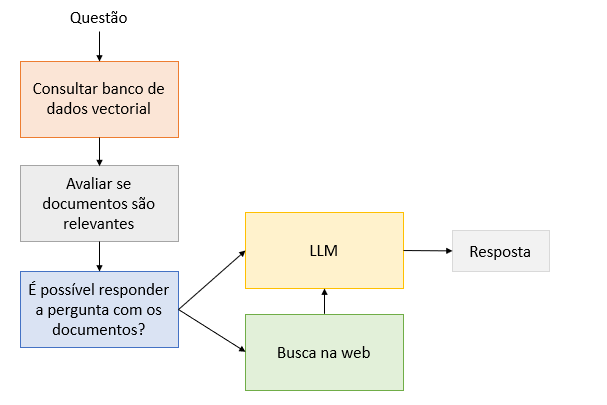

# 3º Definir as ferramentas (tools) e criar o llm com as tools

In [0]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.utilities import DuckDuckGoSearchAPIWrapper
from langchain_community.tools import DuckDuckGoSearchResults
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS #Vector store utilizado
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_core.tools import tool

pdf_bomba = r"/content/drive/MyDrive/01. Cursos ministratos UNICAMP/01. FEQ 0480 - NLP/02. Notebooks/2. Novo curso 2.0/3. Aula 3/N8N/schneider_manual_fit_mancal_05-2020.pdf"
loader = PyPDFLoader(pdf_bomba) #Carrega o pdf
pages = loader.load_and_split() #Cada página do pdf vira um Document do langchain

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size = 1000, #Tamanho de cada fragmento
    chunk_overlap  = 500, #overlap entre fragmentos
    length_function = len, #função de contabilização dos documentos
)
#Quebrar o documento em fragmentos menores
docs = text_splitter.split_documents(pages)

#Importando um word embedding pré treinado gratuito
model_name = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
model_kwargs = {'device': 'cpu'}
encode_kwargs = {'normalize_embeddings': True}
hf = HuggingFaceEmbeddings(
    model_name=model_name,
    model_kwargs=model_kwargs,
    encode_kwargs=encode_kwargs
)
faiss_index = FAISS.from_documents(docs, hf)

@tool
def rag_tool(query:str, k:int = 4):
  """Use esta ferramenta para realizar uma busca vetorial em uma base de conhecimento
  Args:
    query: Pergunta a ser respondida
    k: Número de documentos a serem retornados (k mais semelhantes). Defaut k=4
  Returns:
    Resposta da busca vetorial com os documentos mais relevantes
  """
  documentos_semelhantes = faiss_index.similarity_search(query, k=k)
  return documentos_semelhantes

from pydantic import BaseModel, Field #Classe de estrutura
from typing import Optional, Literal #Tipos de campos

class AvaliarPertinencia(BaseModel):
  avaliacao: Literal["sim", "não"] = Field(description="Se a pergunta pode ser respondida com o contexto fornecido")

avalPert = llm.with_structured_output(AvaliarPertinencia)


@tool
def avaliar_pertinencia(query:str, contexto:str):
  """Use essa ferramenta para avaliar a pertinencia de um contexto para a resposta de uma pergunta
  Args:
    query: Pergunta/solicitação do usuário
    contexto: string de referência que pode ser utilizada para responder o usuário
  Returns:
    pertinencia: sim/não
  """
  prompt = f"""
  Você está recebendo uma pergunta de um usuário e deverá avaliar a pertinência do contexto para a resposta.
  Retorne apenas 'sim' ou 'não'.
  Sim: Se a pergunta pode ser respondida com o contexto fornecido
  Não: Se a pergunta não pode ser respondida com o contexto fornecido

  Pergunta: {query}
  Contexto: {contexto}
  """
  avaliacao = avalPert.invoke(prompt).model_dump()
  return avaliacao.get("avaliacao")


@tool
def search_tool(query:str, k:int = 4):
  """Use esta ferramenta para realizar uma busca de um tema específico
  Args:
    query: Pergunta a ser respondida ou a query de busca na web
    k: Número de resultados a serem retornados. Defaut k=4
  Returns:
    Lista com os resultados da busca
  """
  wrapper = DuckDuckGoSearchAPIWrapper(region="br-pt", max_results=k)
  search = DuckDuckGoSearchResults(api_wrapper=wrapper, output_format="list")
  return search.invoke(query)



In [0]:
retorno = rag_tool.invoke({'query':'qual o processo para troca de oleo', 'k':2})
print(retorno[0].page_content)

In [0]:
avaliar_pertinencia.invoke({'query':'qual o processo para troca de oleo', 'contexto':retorno[0].page_content})

In [0]:
retorno = search_tool.invoke({'query':'qual o processo para troca de oleo', 'k':2})
retorno


# 4º Criar fluxo no LangGraph

In [0]:
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display
from typing_extensions import TypedDict
from typing import Annotated, List
import operator
from langchain.messages import HumanMessage, SystemMessage, AIMessage, ToolMessage

#1º Passo: definir estado (classe de log das mensagens)
# State
class State(TypedDict):
    recuperacao: list #Retorno do invoke do banco de dados vetorial
    contexto: str #trazer o contexto para a resposta do usuário
    #operator.add permite que eu faça um apend na lista de mensagens sem definir explicitamente isso
    messages: Annotated[list, operator.add] #operator.add permite que eu faça um apend

#2º passo: criar os nós
def chamar_llm(estado:State):
  print("Gerando a resposta final")
  pergunta_usuario = estado.get("messages")[0] #pergunta do usuário
  contexto_resposta = estado.get("contexto") #contexto para a resposta do usuário
  if contexto_resposta == "":
    return {"messages": [AIMessage(content="Não foi possível atender a sua solicitação!")]}
  else:
    prompt = f"""
    Responda a pergunta do usuário com base no contexto fornecido.
    Seja sucinto e objetivo.

    Pergunta do usuário: {pergunta_usuario.content}
    Contexto: {contexto_resposta}
    """
    resposta = llm.invoke(prompt)
    return {"messages": [resposta]}

def recuperar_contexto(estado:State):
  print("Recuperando contexto")
  pergunta_usuario = estado.get("messages")[0].content #pergunta do usuário
  retorno = rag_tool.invoke({
      "query": pergunta_usuario,
      "k": 4
  })
  return {"recuperacao": retorno} #adiciono a lista de documentos recuperados no meu estado

def avaliar_rag(estado:State):
  print("Avaliando a pertinência do contexto")
  pergunta_usuario = estado.get("messages")[0].content #pergunta do usuário
  documentos = estado.get("recuperacao") #Lista documentos retornados pela ferramenta de RAG
  results = []
  for doc in documentos:
    texto_documento = doc.page_content
    avaliacao = avaliar_pertinencia.invoke({
        "query": pergunta_usuario,
        "contexto": texto_documento
    })
    if avaliacao == "sim":
      results.append(texto_documento)
  if len(results) > 0:
    return {"contexto": "\n".join(results)}
  else:
    return {"contexto": ""}

def route_node(estado:State):
  contexto = estado.get("contexto")
  if contexto == "":
    print("Chamando a pesquisa")
    return "chamar_pesquisa"
  else:
    print("Chamando o LLM")
    return "chamar_llm"

def pesquisa_web(estado:State):
  print("Fazendo a pesquisa na web")
  pergunta_usuario = estado.get("messages")[0].content #pergunta do usuário
  #Chamar a tool de search web
  pesquisa_web = search_tool.invoke({
      "query": pergunta_usuario,
      "k": 4
  })
  results = []
  for doc in pesquisa_web:
    results.append(doc['snippet'])
  #Formatar para uma string unica
  results = "\n".join(results)
  return {"contexto": results}



In [0]:
# Construir fluxo
agente = StateGraph(State)

#Definir nós
agente.add_node("recuperar_contexto", recuperar_contexto)
agente.add_node("avaliar_rag", avaliar_rag)
agente.add_node("pesquisa_web", pesquisa_web)
agente.add_node("chamar_llm", chamar_llm)

#Definir arestas
agente.add_edge(START, "recuperar_contexto")
agente.add_edge("recuperar_contexto", "avaliar_rag")
agente.add_conditional_edges(
    "avaliar_rag", route_node,
    {
        "chamar_pesquisa": "pesquisa_web",
        "chamar_llm": "chamar_llm"
    }
)
agente.add_edge("pesquisa_web", "chamar_llm")
agente.add_edge("chamar_llm", END)


#Compilar
agente = agente.compile()

# Mostrar o fluxo
display(Image(agente.get_graph(xray=True).draw_mermaid_png()))


In [0]:
#Interagir com o agente

input = HumanMessage(
    content = "Qual a previsão do tempo para campinas hoje?"
)
resposta = agente.invoke({"messages": [input]})
#imprimir resposta final
print("\n\nResposta do agente\n\n")
print(resposta.get("messages")[-1].content)

In [0]:
#outra forma de visualizar

for m in resposta.get("messages"):
  m.pretty_print()